<a href="https://colab.research.google.com/github/TejasDharmale/complex-adaptive-systems/blob/main/CAS_assignment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 7 - Optimal control

    Name: Tejas Dharmale
    Student #: s1190137

In [1]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr

# Exericse 1: Linear Quadratic Control

Simulate the completely observed discrete-time stochastic harmonic oscillator without control. Use $\omega^2=1$ and $\sigma_x^2$=0.01.

## Solution 1.1 (1 point)

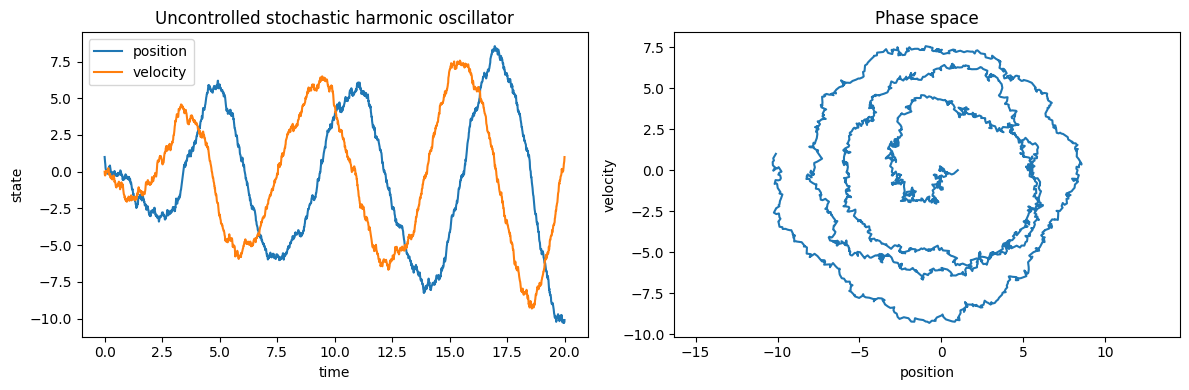

In [2]:
omega2 = 1.0
sigma2_x = 0.01
tau = 0.01
T = 2000            # number of steps (total time = T * tau = 20)
A = jnp.array([[0.0, 1.0],
               [-omega2, 0.0]])
B = jnp.array([[0.0],
               [1.0]])
A_tilde = tau * A + jnp.eye(2)
B_tilde = tau * B
W = sigma2_x * jnp.eye(2)

def simulate_step_uncontrolled(carry, t):
    x, key = carry
    key, subkey = jr.split(key)
    noise = jr.multivariate_normal(subkey, jnp.zeros(2), W)
    u = jnp.zeros(1)
    next_x = A_tilde @ x + B_tilde @ u + noise
    return (next_x, key), next_x

x0 = jnp.array([1.0, 0.0])
key = jr.PRNGKey(0)
_, xs = jax.lax.scan(simulate_step_uncontrolled, (x0, key), jnp.arange(T))
xs = jnp.vstack([x0, xs])
time = jnp.arange(T + 1) * tau
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(time, xs[:, 0], label="position")
axes[0].plot(time, xs[:, 1], label="velocity")
axes[0].set_xlabel("time")
axes[0].set_ylabel("state")
axes[0].set_title("Uncontrolled stochastic harmonic oscillator")
axes[0].legend()
axes[1].plot(xs[:, 0], xs[:, 1])
axes[1].set_xlabel("position")
axes[1].set_ylabel("velocity")
axes[1].set_title("Phase space")
axes[1].axis("equal")
plt.tight_layout()
plt.show()

In [3]:
# 1. State of the system is [position, velocity] of a mass on the spring. In matrix A, we have the physics:
# position goes to velocity, and the spring reacts to that by pulling it with -omega^2 * position
# 2. The time step is taken to be tau, hence one step forward is x_next = A_tilde @ x, where A_tilde = tau * A + I (Euler method).
# 3. With every step, we add a tiny Gaussian noise with covariance matrix W = sigma_x^2 * I. This introduces stochasticity in our oscillator. Control input u is zero
# 4. With jax.lax.scan, we iterate this step T number of times starting with x0 = [1, 0]. Plots show position and velocity versus time (wavy curves) and phase space (wiggling circle).

## Exercise 1.2 (3 points)

Compute the Linear Quadratic Regulator for the completely observed discrete-time stochastic harmonic oscillator. You may use 'scipy.linalg.solve_discrete_are' to compute the S matrix. You can assume that $Q = \tau I$ and $R = \tau$, and use the origin as target. Use $\tilde{A} = \tau A + I$ and $\tilde{B}=\tau B$ to solve the algebraic Riccati equation.

## Solution 1.2

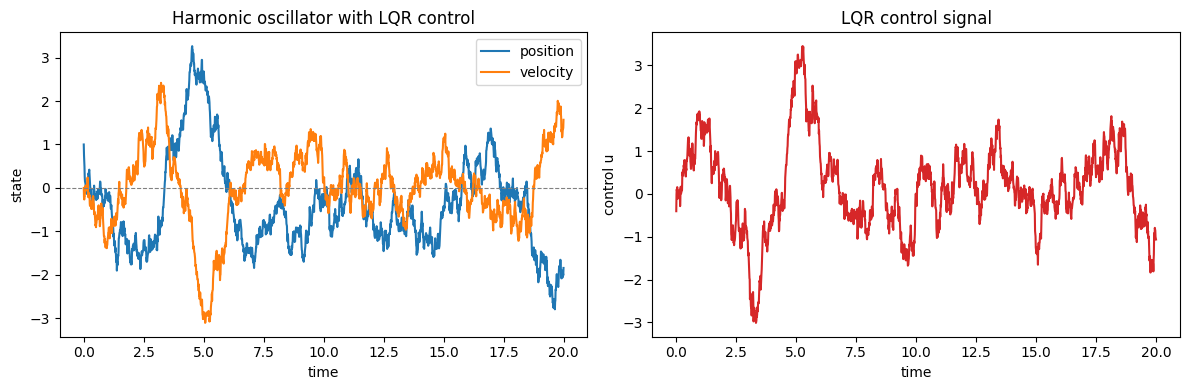

In [5]:
## Control theory utilities
from scipy.linalg import solve_discrete_are

class LQR:
    def __init__(self, A: jnp.array, B: jnp.array, W: jnp.array,
                 Q: jnp.array, R: jnp.array) -> None:

        self.n_state = A.shape[0]
        self.n_control = B.shape[1]

        self.A = A
        self.B = B
        self.W = W

        self.Q = Q
        self.R = R

        # solution to the DARE
        self.S = jnp.array(solve_discrete_are(jnp.asarray(A), jnp.asarray(B),
                                              jnp.asarray(Q), jnp.asarray(R)))

        # Feedback gain matrix
        self.L =jnp.linalg.solve(R + B.T @ self.S @ B, B.T @ self.S @ A)

    def control(self, x):
        return -self.L @ x

    def reward(self, x, u):
      return -(x @ self.Q @ x + u @ self.R @ u)

#DEFINE YOUR VARIABLES
Q = tau * jnp.eye(2)
R = tau * jnp.eye(1)

lqr = LQR(A_tilde, B_tilde, W, Q, R)

def simulate_step(carry, t):
    x, key = carry
    key, subkey = jr.split(key)
    noise = jr.multivariate_normal(subkey, jnp.zeros(2), W)
    u = lqr.control(x)
    next_x = A_tilde @ x + B_tilde @ u + noise
    return (next_x, key), (next_x, u)

x0 = jnp.array([1.0, 0.0])
key = jr.PRNGKey(0)
_, (xs_lqr, us_lqr) = jax.lax.scan(simulate_step, (x0, key), jnp.arange(T))
xs_lqr = jnp.vstack([x0, xs_lqr])
time = jnp.arange(T + 1) * tau

#YOUR PLOTTING CODE HERE
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(time, xs_lqr[:, 0], label="position")
axes[0].plot(time, xs_lqr[:, 1], label="velocity")
axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("time")
axes[0].set_ylabel("state")
axes[0].set_title("Harmonic oscillator with LQR control")
axes[0].legend()

axes[1].plot(time[1:], us_lqr[:, 0], color="tab:red")
axes[1].set_xlabel("time")
axes[1].set_ylabel("control u")
axes[1].set_title("LQR control signal")

plt.tight_layout()
plt.show()

In [ ]:
# 1.] Q = tau * I punishes deviation from the origin, while R = tau punishes control effort.
#    The matrices A_tilde and B_tilde are used for LQR computations, as required by the task.
# 2.] S solves the discrete algebraic Riccati equation (cost to go for each state), and the
#    control gain is L = inv(R + B' * S * B) * B' * S * A. Optimal control is u = -L*x.
# 3.] The reward function is negative quadratic cost, -(x' Q x + u' R u). Hence, it is close to 0
#    when the oscillator is at rest (at the origin) and there is no control applied.
# 4.] At each simulation step, LQR controller is computed, dynamics from 1.1 are applied with noise,
#    and the figures show convergence of states to origin and vanishing control.

## Exercise 1.3 (1 point)

Compare the reward over time of the LQR controller with no control.

## Solution 1.3

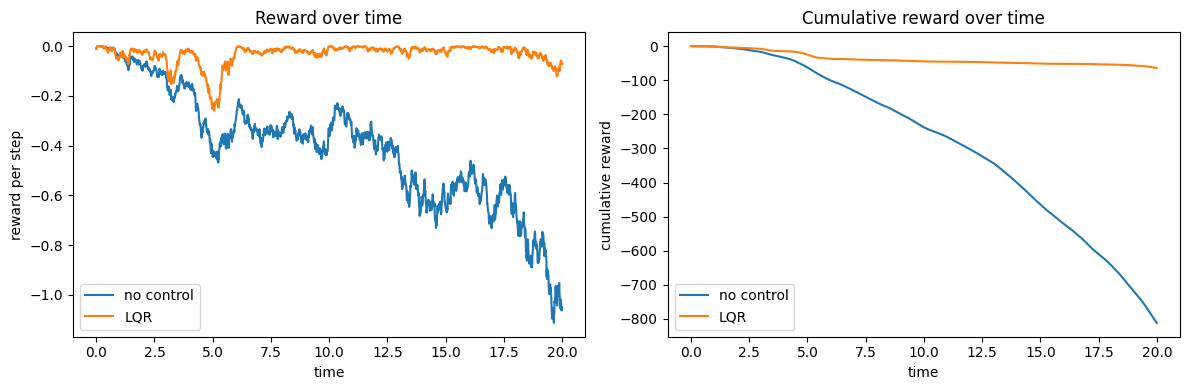

Total reward, no control: -811.48206
Total reward, LQR:        -63.3588


In [6]:
us_none = jnp.zeros((T, 1))
rewards_none = jax.vmap(lqr.reward)(xs[:-1], us_none)
rewards_lqr = jax.vmap(lqr.reward)(xs_lqr[:-1], us_lqr)
time_r = jnp.arange(T) * tau
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(time_r, rewards_none, label="no control")
axes[0].plot(time_r, rewards_lqr, label="LQR")
axes[0].set_xlabel("time")
axes[0].set_ylabel("reward per step")
axes[0].set_title("Reward over time")
axes[0].legend()
axes[1].plot(time_r, jnp.cumsum(rewards_none), label="no control")
axes[1].plot(time_r, jnp.cumsum(rewards_lqr), label="LQR")
axes[1].set_xlabel("time")
axes[1].set_ylabel("cumulative reward")
axes[1].set_title("Cumulative reward over time")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Total reward, no control:", jnp.sum(rewards_none))
print("Total reward, LQR:       ", jnp.sum(rewards_lqr))

In [7]:
#  At each step, the reward is given by -(x^T Q x + u^T R u) using the lqr.reward function for
# both cases where u = 0 for the uncontrolled case 1.1 and u = -Lx for the LQR case 1.2
#Both cases use the same random seed, hence the same noise is used in both cases for a fair
# comparison
#In the uncontrolled case, the reward continues to decrease into the negatives since the
# oscillator never stops oscillating
#In the LQR case, the reward is initially negative but then stabilizes to around 0 after the
# system stabilizes; hence, the reward is much higher in the LQR case than in the uncontrolled case.

# Exercise 2: Linear Quadratic Gaussian control

Under partial observability or noisy measurements, the LQR can be made more robust by estimating the current state (also known as filtering). In the exercise, we will implement the LQG, which extends the LQR with optimal filtering.

## Exercise 2.1 (1 point)

Extend the discrete-time stochastic harmonic oscillator to have noisy observations for both the position and velocity. You can either show the true state and observations in separate plots, or plot the observations over the true state in the same plot.

## Solution 2.1

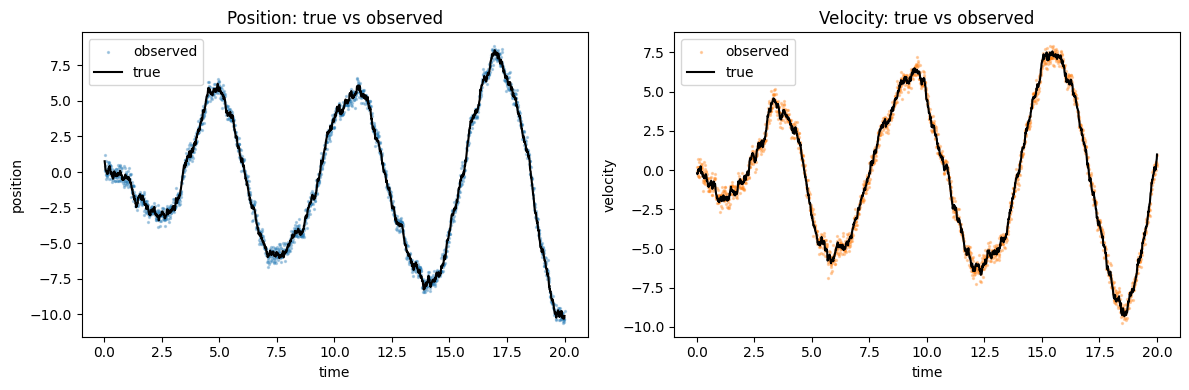

In [8]:
sigma2_y = 0.1
C = jnp.eye(2)
V = sigma2_y * jnp.eye(2)

def simulate_step_observed(carry, t):
    x, key = carry
    key, subkey1, subkey2 = jr.split(key, 3)
    u = jnp.zeros(1)
    process_noise = jr.multivariate_normal(subkey1, jnp.zeros(2), W)
    next_x = A_tilde @ x + B_tilde @ u + process_noise
    measurement_noise = jr.multivariate_normal(subkey2, jnp.zeros(2), V)
    y = C @ next_x + measurement_noise
    return (next_x, key), (next_x, y)

x0 = jnp.array([1.0, 0.0])
key = jr.PRNGKey(0)
_, (xs_true, ys_obs) = jax.lax.scan(simulate_step_observed, (x0, key), jnp.arange(T))
time_obs = jnp.arange(1, T + 1) * tau

# Plot observations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(time_obs, ys_obs[:, 0], s=2, alpha=0.3, color="tab:blue", label="observed")
axes[0].plot(time_obs, xs_true[:, 0], color="black", label="true")
axes[0].set_xlabel("time")
axes[0].set_ylabel("position")
axes[0].set_title("Position: true vs observed")
axes[0].legend()
axes[1].scatter(time_obs, ys_obs[:, 1], s=2, alpha=0.3, color="tab:orange", label="observed")
axes[1].plot(time_obs, xs_true[:, 1], color="black", label="true")
axes[1].set_xlabel("time")
axes[1].set_ylabel("velocity")
axes[1].set_title("Velocity: true vs observed")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
# 1]The actual state evolves according to the same dynamic model without any control action (u=0) as described in problem 1.1.
# 2]At each time step, the noisy observation y = Cx + noisy measurement is formed with C = I
# being the matrix that means that both position and velocity are measured and V = sigma_y^2 * I is the measurement noise variance.
# 3]Two different keys are used for each time step: one for the process noise and another for the measurement noise.
# 4]The figure below illustrates the noisy measurements as a noisy cloud of points around the smoothly evolving actual state.
# This explains why the actual state can not be recovered from the measurements directly.

## Exercise 2.2 (2 points)

Compute the optimal control solution with the LQG for the partially observed discrete-time stochastic harmonic oscillator.

## Solution 2.2

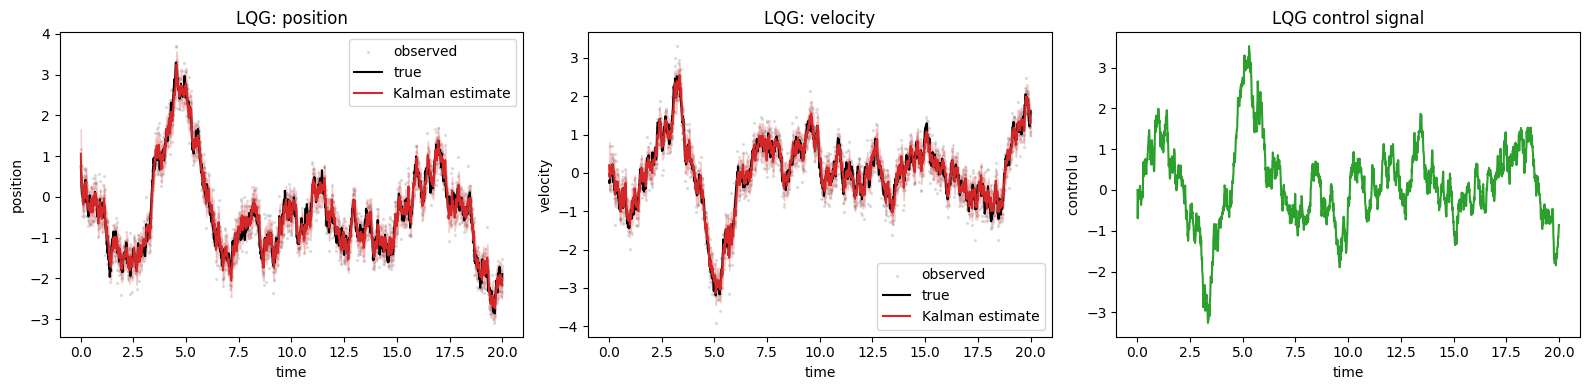

In [10]:
from scipy.linalg import solve_discrete_are
import numpy as np
class LQG:

    def __init__(self, A: jnp.array, B: jnp.array, W: jnp.array,
                 Q: jnp.array, R: jnp.array, C: jnp.array, V: jnp.array) -> None:

        self.n_state = A.shape[0]
        self.n_control = B.shape[1]

        self.A = A
        self.B = B
        self.W = W

        self.C = C
        self.V = V

        self.Q = Q
        self.R = R

        # solution to the DARE (same as LQR)
        self.S = jnp.array(solve_discrete_are(np.asarray(A), np.asarray(B),
                                              np.asarray(Q), np.asarray(R)))

        # Feedback gain matrix (same as LQR)
        self.L = jnp.linalg.solve(R + B.T @ self.S @ B, B.T @ self.S @ A)

    def control(self, x):
        # x here is the state ESTIMATE mu
        return -self.L @ x

    def reward(self, x, u):
        return -(x @ self.Q @ x + u @ self.R @ u)

    def kalman_filter(self, mu, Sigma, y, uk=0.0):
        """
        Kalman Filter function for state estimation

        Input
        mu: np.array        current mean state estimate
        Sigma: np.array     current uncertainty estimate
        y: np.array         last observation
        uk: np.array        last control signal

        Return
        muk: np.array       updated mean state estimate
        Sigmak: np.array    updated uncerstainty estimate

        """
        uk = jnp.atleast_1d(uk)


        mu_pred = self.A @ mu + self.B @ uk
        Sigma_pred = self.A @ Sigma @ self.A.T + self.W


        S_y = self.C @ Sigma_pred @ self.C.T + self.V
        K = Sigma_pred @ self.C.T @ jnp.linalg.inv(S_y)
        muk = mu_pred + K @ (y - self.C @ mu_pred)
        Sigmak = (jnp.eye(self.n_state) - K @ self.C) @ Sigma_pred

        return muk, Sigmak

#DEFINE YOUR VARIABLES
Q = tau * jnp.eye(2)
R = tau * jnp.eye(1)
sigma2_y = 0.1
C = jnp.eye(2)
V = sigma2_y * jnp.eye(2)

lqg = LQG(A_tilde, B_tilde, W, Q, R, C, V)

def simulate_step(carry, t):
    x, mu, Sigma, key = carry
    key, subkey1, subkey2 = jax.random.split(key, 3)

    # control from the estimate, not the true state
    u = lqg.control(mu)

    # true state moves with process noise
    next_x = A_tilde @ x + B_tilde @ u + jr.multivariate_normal(subkey1, jnp.zeros(2), W)

    # noisy observation of the new state
    y = C @ next_x + jr.multivariate_normal(subkey2, jnp.zeros(2), V)

    # update the estimate with the Kalman filter
    next_mu, next_Sigma = lqg.kalman_filter(mu, Sigma, y, u)

    return (next_x, next_mu, next_Sigma, key), (next_x, y, u, next_mu, next_Sigma)

x0 = jnp.array([1.0, 0.0])
mu0 = jnp.zeros(2)
Sigma0 = jnp.eye(2)
key = jr.PRNGKey(0)

_, (xs_lqg, ys_lqg, us_lqg, mus_lqg, Sigmas_lqg) = jax.lax.scan(
    simulate_step, (x0, mu0, Sigma0, key), jnp.arange(T))
time_lqg = jnp.arange(1, T + 1) * tau

#YOUR PLOTTING CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

labels = ["position", "velocity"]
for i in range(2):
    std = jnp.sqrt(Sigmas_lqg[:, i, i])
    axes[i].scatter(time_lqg, ys_lqg[:, i], s=2, alpha=0.2, color="gray", label="observed")
    axes[i].plot(time_lqg, xs_lqg[:, i], color="black", label="true")
    axes[i].plot(time_lqg, mus_lqg[:, i], color="tab:red", label="Kalman estimate")
    axes[i].fill_between(time_lqg, mus_lqg[:, i] - 2 * std, mus_lqg[:, i] + 2 * std,color="tab:red", alpha=0.2)
    axes[i].set_xlabel("time")
    axes[i].set_ylabel(labels[i])
    axes[i].set_title(f"LQG: {labels[i]}")
    axes[i].legend()
axes[2].plot(time_lqg, us_lqg[:, 0], color="tab:green")
axes[2].set_xlabel("time")
axes[2].set_ylabel("control u")
axes[2].set_title("LQG control signal")

plt.tight_layout()
plt.show()

In [11]:
# 1.The controller is the same as for LQR: S solves the Riccati equation, L is the feedback gain, but the
#   control law u = -L mu is applied based on the estimated state rather than the true state.
# 2.In the Kalman filter, the next state and the error covariance are predicted by the dynamical model
#   and then corrected by incorporating the new noisy observation, where the Kalman gain K
#   determines the weight between the prediction and the measurement.
# 3.At each iteration, the control is computed based on the state estimate, the state is updated
#   by adding process noise, the noisy measurement is computed, and the state estimate is
#   updated by applying the Kalman filter.
# 4.From the plots, we can see that the state estimate starts from an incorrect initial guess of zero,
#   then quickly converges to the true state and tracks it much smoother compared to the measurements
#   while reducing the error covariance and stabilizing the oscillator at the origin.

## Exercise 2.3 (2 points)

Show the cummulative reward over time with different levels of observation noise, and compare it with the reward of the LQR. which receives noisy observations.

## Solution 2.3

sigma_y^2 = 0.01   total reward LQG:  -72.478   LQR:  -72.634
sigma_y^2 = 0.1    total reward LQG:  -73.312   LQR:  -76.292
sigma_y^2 = 0.5    total reward LQG:  -74.854   LQR:  -92.574
sigma_y^2 = 1.0    total reward LQG:  -76.023   LQR: -112.933


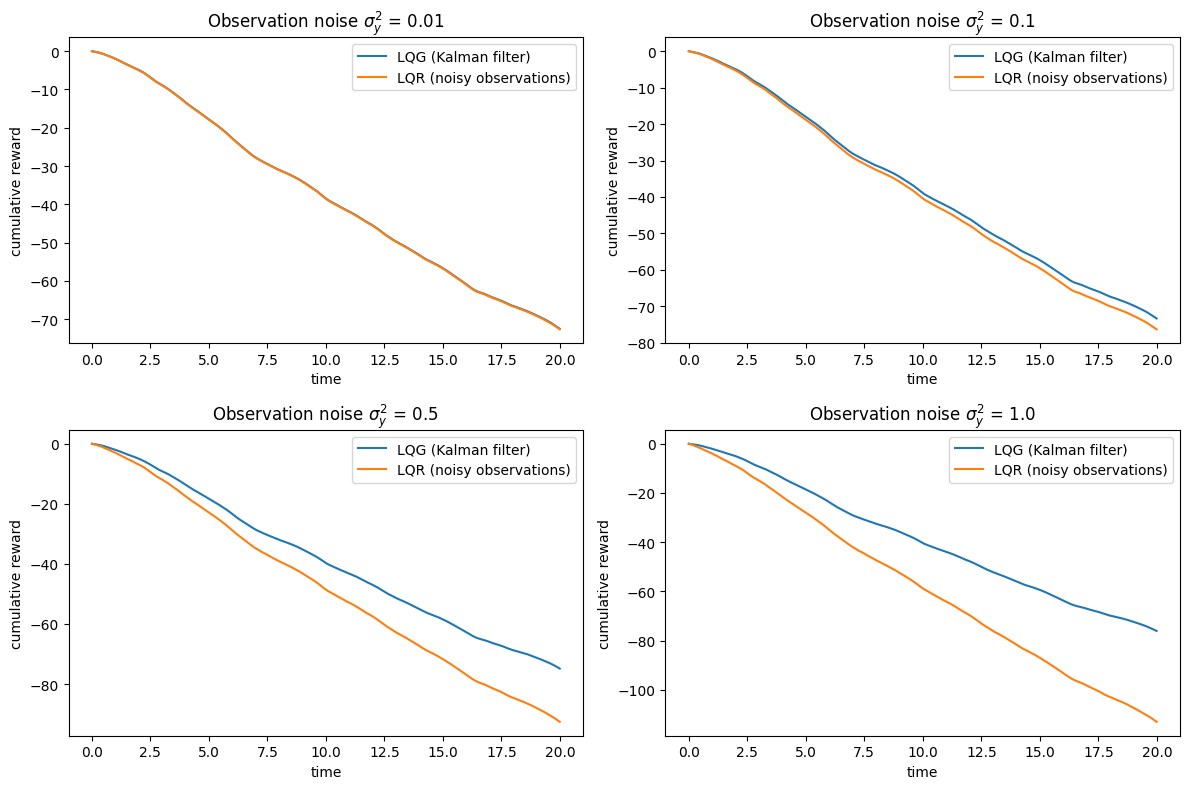

In [12]:
noise_levels = [0.01, 0.1, 0.5, 1.0]
n_runs = 20
x0 = jnp.array([1.0, 0.0])

def run_lqg(key, model):

    key, k0 = jr.split(key)
    y0 = model.C @ x0 + jr.multivariate_normal(k0, jnp.zeros(2), model.V)

    def step(carry, t):
        x, mu, Sigma, key = carry
        key, k1, k2 = jr.split(key, 3)
        u = model.control(mu)
        r = model.reward(x, u)
        next_x = A_tilde @ x + B_tilde @ u + jr.multivariate_normal(k1, jnp.zeros(2), W)
        y = model.C @ next_x + jr.multivariate_normal(k2, jnp.zeros(2), model.V)
        next_mu, next_Sigma = model.kalman_filter(mu, Sigma, y, u)
        return (next_x, next_mu, next_Sigma, key), r
    _, rewards = jax.lax.scan(step, (x0, y0, model.V, key), jnp.arange(T))
    return rewards

def run_lqr_noisy(key, model):
    key, k0 = jr.split(key)
    y0 = model.C @ x0 + jr.multivariate_normal(k0, jnp.zeros(2), model.V)

    def step(carry, t):
        x, y, key = carry
        key, k1, k2 = jr.split(key, 3)
        u = lqr.control(y)
        r = lqr.reward(x, u)
        next_x = A_tilde @ x + B_tilde @ u + jr.multivariate_normal(k1, jnp.zeros(2), W)
        next_y = model.C @ next_x + jr.multivariate_normal(k2, jnp.zeros(2), model.V)
        return (next_x, next_y, key), r
    _, rewards = jax.lax.scan(step, (x0, y0, key), jnp.arange(T))
    return rewards
keys = jr.split(jr.PRNGKey(0), n_runs)
time_r = jnp.arange(T) * tau
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i, s2 in enumerate(noise_levels):
    V_i = s2 * jnp.eye(2)
    model = LQG(A_tilde, B_tilde, W, Q, R, C, V_i)
    rewards_lqg = jax.vmap(lambda k: run_lqg(k, model))(keys).mean(axis=0)
    rewards_lqr = jax.vmap(lambda k: run_lqr_noisy(k, model))(keys).mean(axis=0)
    axes[i].plot(time_r, jnp.cumsum(rewards_lqg), label="LQG (Kalman filter)")
    axes[i].plot(time_r, jnp.cumsum(rewards_lqr), label="LQR (noisy observations)")
    axes[i].set_xlabel("time")
    axes[i].set_ylabel("cumulative reward")
    axes[i].set_title(f"Observation noise $\\sigma_y^2$ = {s2}")
    axes[i].legend()
    print(f"sigma_y^2 = {s2:<5}  total reward LQG: {jnp.sum(rewards_lqg):8.3f}   "
          f"LQR: {jnp.sum(rewards_lqr):8.3f}")
plt.tight_layout()
plt.show()

In [13]:
# 1] Comparison of two controllers who use the noisy observation. For LQR it is (u = -L y) and for LQG it is (u = -L mu). Both use the same gain L
# 2]The reward is always based on the true state and control regardless of the amount of noise, at several values of the noise level. And both controllers have the same noise and initial observation.
# 3] All scenarios are run 20 times with a different seed using jax.vmap, and the rewards are averaged, so that no single curve depends on a lucky/unlucky run.
# 4] For small values of noise both controllers give similar results, but when the noise increases, the LQR starts reacting to it and its total reward drops sharply, whereas LQG remains robust to the noise changes.